In [1]:
import os
os.environ['R_HOME'] = '/Users/soeren.becker/micromamba/envs/env_pertpy/lib/R'

In [2]:
import glob
import numpy as np
import pandas as pd
import pertpy as pt
import scanpy as sc
import anndata as ad
import seaborn as sns
import decoupler as dc
import matplotlib.pyplot as plt

from pathlib import Path
from rpy2 import robjects as ro
from rpy2.robjects import numpy2ri, pandas2ri
from rpy2.robjects.conversion import get_conversion, localconverter
from rpy2.robjects.packages import importr
from scipy.sparse import issparse
from tqdm.auto import tqdm

/Users/soeren.becker/micromamba/envs/env_pertpy/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


In [3]:
edger = importr("edgeR")

In [42]:
def filter_genes(adata, min_frac = 0.05):
    mask = np.asarray((adata.X > 0).mean(axis=0) > min_frac).squeeze()
    valid_genes = adata.var_names[mask]
    return adata[:, valid_genes]


def prepare_data(path, min_frac=0.05, min_cells = 40):
    adata = sc.read_h5ad(path)
    adata_filtered = filter_genes(adata, min_frac=min_frac)
    adata_filtered.layers["counts"] = adata_filtered.X
    pdata = dc.get_pseudobulk(
        adata_filtered,
        sample_col='donor',
        groups_col=['bc1_well'],
        layer='counts',
        mode="sum",
        min_cells=0,
        min_counts=0,
        remove_empty=False,
    )
    pdata = pdata[pdata.obs.psbulk_n_cells > min_cells]
    return pdata


def run_DE(pdata):
    all_results = []

    for baseline in pdata.obs.bc1_well.unique():
    
        edgr = pt.tl.EdgeR(pdata, design="~donor+bc1_well")
    
        compares = pdata.obs.bc1_well.unique()
        compares = [c for c in compares if c != baseline]
        
        res_df = edgr.compare_groups(
            pdata,
            column="bc1_well",
            baseline=baseline,
            groups_to_compare=compares,
        )
        
        res_df.loc[:, "baseline"] = baseline
        all_results.append(res_df)
    
    results = pd.concat(all_results, ignore_index=True)
    results.loc[:, "significant_0_05"] = results.loc[:, "adj_p_value"] < 0.05
    return results


def make_heatmap(results, path=None, show=False):
    r2 = results.groupby(["baseline", "contrast"])["significant_0_05"].sum().to_frame().reset_index()

    df_pivot = r2.pivot(
        index="baseline",
        columns="contrast",
        values="significant_0_05",
    ).astype(float)
    order = ["H7", "H8", "H9", "H10", "H11", "H12"]
    df_pivot = df_pivot.loc[order, order][::-1]
    
    sns.heatmap(df_pivot, square=True, annot=True)
    if path:
        plt.savefig(path, bbox_inches="tight", pad_inches=0)
    if show:
        plt.show()
    plt.close()

In [43]:
paths = glob.glob("/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_*.h5ad")
paths

['/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_ILC.h5ad',
 '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_CD56-bright_NK.h5ad',
 '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_CD8_Naive.h5ad',
 '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_HSPC.h5ad',
 '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_Plasmablast.h5ad',
 '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_CD4_Memory.h5ad',
 '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_pDC.h5ad',
 '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_MAIT.h5ad',
 '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_CD8_Memory.h5ad',
 '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_NKT.h5ad',
 '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_CD16_Mono.h5ad',
 '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_other.h5ad',
 '/Users/soeren.becker/repo

In [44]:
paths = [
    # '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_ILC.h5ad',
    '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_CD56-bright_NK.h5ad',
    '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_CD8_Naive.h5ad',
    # '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_HSPC.h5ad',
    # '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_Plasmablast.h5ad',
    '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_CD4_Memory.h5ad',
    # '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_pDC.h5ad',
    '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_MAIT.h5ad',
    '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_CD8_Memory.h5ad',
    '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_NKT.h5ad',
    '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_CD16_Mono.h5ad',
    # '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_other.h5ad',
    '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_cDC.h5ad',
    '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_CD4_Naive.h5ad',
    '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_B_Intermediate_Memory.h5ad',
    #'/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_Platelet.h5ad',
    '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_B_Naive.h5ad',
    '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_Treg.h5ad',
    '/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_CD14_Mono.h5ad',
'/Users/soeren.becker/repos/HumanCytokineDict/data/PBS/adata_pbs_CD56-dim_NK.h5ad'
]

In [45]:
res_dir = "/Users/soeren.becker/repos/HumanCytokineDict/results/01_DEGs/pbs-vs-pbs"

In [46]:
for path in paths:
    pdata = prepare_data(path)
    if pdata.shape[0] < 10: continue
    assert len(pdata.obs.cell_type_new.unique()) == 1
    celltype = pdata.obs.cell_type_new.unique()[0]
    
    results = run_DE(pdata)
    results.to_csv(os.path.join(res_dir, f"results_{celltype}.csv"))
    make_heatmap(results, path=os.path.join(res_dir, f"heatmap_{celltype}.png"))
    # break

/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_77930/3184243601.py:10: ImplicitModificationWarning: Setting element `.layers['counts']` of view, initializing view as actual.
  adata_filtered.layers["counts"] = adata_filtered.X


• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model


/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_77930/3184243601.py:10: ImplicitModificationWarning: Setting element `.layers['counts']` of view, initializing view as actual.
  adata_filtered.layers["counts"] = adata_filtered.X


• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model


/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_77930/3184243601.py:10: ImplicitModificationWarning: Setting element `.layers['counts']` of view, initializing view as actual.
  adata_filtered.layers["counts"] = adata_filtered.X


...

/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_77930/3184243601.py:10: ImplicitModificationWarning: Setting element `.layers['counts']` of view, initializing view as actual.
  adata_filtered.layers["counts"] = adata_filtered.X


• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model


/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_77930/3184243601.py:10: ImplicitModificationWarning: Setting element `.layers['counts']` of view, initializing view as actual.
  adata_filtered.layers["counts"] = adata_filtered.X


• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model
• Calculating NormFactors
• Estimating Dispersions
• Fitting linear model


OSError: Cannot save file into a non-existent directory: '/Users/soeren.becker/repos/HumanCytokineDict/results/01_DEGs/pbs-vs-pbs/results_B Intermediate'

In [30]:
pdata

View of AnnData object with n_obs × n_vars = 0 × 8183
    obs: 'donor', 'bc1_well', 'sample', 'species', 'bc1_wind', 'cytokine', 'treatment', 'cell_type', 'cell_type_new', 'psbulk_n_cells', 'psbulk_counts'
    var: 'n_cells'
    layers: 'psbulk_props'

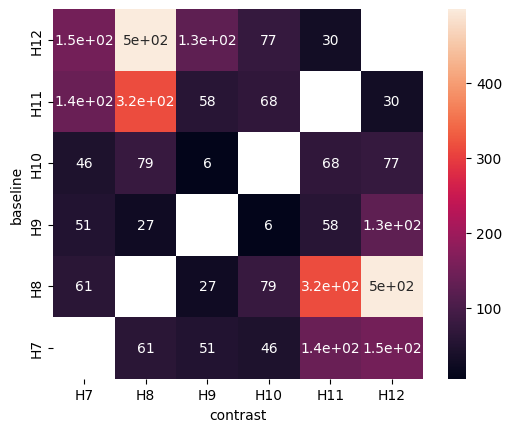